# Highly rated TV series from metadata
**Machine Learning Algorithms, Midterm, Week 5**  
**Bekzat Rashiduly and Gapar Galym, SE-2418**

Can genre, premiere year, episode runtime, country and network/platform distinguish English-language scripted series rated at least 8/10 on TVmaze from series below 8/10? Viewers and catalogue curators could use metadata-based scores to shortlist similar series when a rating is unavailable. We test this idea on an existing rated catalogue, so transfer to unrated or newly released shows remains an untested hypothesis.

**Source: [TVmaze](https://www.tvmaze.com), collected through its [public API](https://www.tvmaze.com/api). Data license: [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).** TVmaze provides the observations, ratings and plot summaries. We transform the observations into a cleaned table, binary label and derived features. Keep attribution and the same data license when redistributing this snapshot.

The teacher approved the topic on 5 October 2026 and requested visible TVmaze attribution in the notebook and slides. The label is **1 when rating >= 8**, otherwise **0**. A missing rating is an unknown label and is excluded. The threshold was registered before collection and modelling and stays fixed.

## 1. Data card and source checks
One row describes one unique TVmaze series. The collector requests the fixed show-index pages **0 to 59**, chosen before model evaluation, without a token or account. This is a finite catalogue cohort rather than a random sample of all TVmaze shows. The raw JSON, per-request timestamp, response status and SHA-256 hash are in `data/raw/midterm_2026-10-06/`.

The snapshot includes structured features and plot summaries. Midterm models use structured features only. We retain the exact same plot texts and labels for the Final. Raw objects also contain information intentionally excluded from modelling.

| Cleaned field | Type and meaning | Role |
|---|---|---|
| show_id | Integer TVmaze identifier | Joins, deduplication and frozen split only |
| name | Series title | Human-readable error examples only |
| source_url | TVmaze series page | Attribution and traceability only |
| language | Source language | English eligibility check |
| show_type | TVmaze format | Scripted eligibility check |
| premiered | ISO date, may be missing | Audit and premiere-year derivation |
| premiere_year | Numeric year, may be missing | Model feature |
| runtime_minutes | Advertised episode runtime, may be missing | Model feature |
| network | Network name or Unknown | Model feature |
| web_channel | Web platform name or None | Model feature |
| broadcast_country | Network/platform country code or Unknown | Model feature, not a production-country claim |
| distribution | Broadcast, Streaming, Hybrid or Unknown | Model feature |
| genres | JSON list of source genres | Multi-label model feature |
| rating | Observed TVmaze user score, 0 to 10 | Label construction and error audit only |
| high_rated | Binary label from the fixed 8/10 threshold | Supervised target |
| plot_summary | HTML-free plot text | Reserved for the Final |

`split_assignments.csv` separately stores show_id, train/test membership and cv_fold. Fold -1 belongs to the held-out test set. These are experiment-control fields, not model inputs.

The source check records the public API licensing page and both robots URLs. A 404 at the API robots URL means that file does not exist. Collection uses the expressly documented public API, respects its rate limits, and avoids website paths restricted by the website robots file. We collect show objects, not private user profiles.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import cross_validate
from sklearn.metrics import (make_scorer, f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
import sklearn, joblib

ROOT = Path.cwd()
if not (ROOT / 'code' / 'project.py').exists() and (ROOT / 'tvmaze_project' / 'code' / 'project.py').exists():
    ROOT = ROOT / 'tvmaze_project'
assert (ROOT / 'code' / 'project.py').exists(), 'Run this notebook from the extracted project folder.'
sys.path.insert(0, str(ROOT / 'code'))
from project import (load_raw, clean_raw, freeze_splits, make_models,
                     positive_scores, FEATURES, NUMERIC, CATEGORICAL, SEED, THRESHOLD)
OUT = ROOT / 'results' / 'midterm'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
(ROOT / 'models').mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
raw, manifest = load_raw(ROOT)
source_check = json.loads((ROOT / 'data' / 'raw' / manifest['snapshot'] / 'source_check.json').read_text())
display(pd.DataFrame([{'Snapshot': manifest['snapshot'], 'Collection date (Almaty)': manifest['collection_date_almaty'],
    'Started UTC': manifest['started_utc'], 'Finished UTC': manifest['finished_utc'],
    'API pages': len(manifest['pages']), 'Raw objects': len(raw), 'Authentication': 'None'}]).T.rename(columns={0:'Value'}))
display(pd.DataFrame(source_check['requests']))
print('PASS: all raw page hashes and row counts match the collection manifest.')
print('License:', source_check['data_license'], source_check['license_url'])

Matplotlib is building the font cache; this may take a moment.


,Value
Snapshot,midterm_2026-10-06
Collection date (Almaty),2026-10-06
Started UTC,2026-10-06T07:05:01.119899+00:00
Finished UTC,2026-10-06T07:06:25.305317+00:00
API pages,60
Raw objects,14055
Authentication,None


,url,http_status,sha256,text,interpretation,licensing_excerpt
0,https://www.tvmaze.com/robots.txt,200,147f7dcee59dcb43f088cc58da168c87cbef26197ea32d...,Sitemap: https://www.tvmaze.com/sitemaps/recap...,NaN,NaN
1,https://api.tvmaze.com/robots.txt,404,NaN,NaN,No robots file at API host; use the expressly ...,NaN
2,https://www.tvmaze.com/api,200,697b7180721a82758b40158e4748364816419c3766d160...,NaN,NaN,Use of the TVmaze API is licensed by CC BY-SA....


PASS: all raw page hashes and row counts match the collection manifest.
License: CC BY-SA 4.0 https://creativecommons.org/licenses/by-sa/4.0/


In [2]:
raw_fields = sorted({field for item in raw for field in item})
roles = {
 'id':'Identifier, excluded', 'url':'Source link, excluded', 'name':'Title, excluded',
 'type':'Eligibility only', 'language':'Eligibility only', 'genres':'Genre features',
 'runtime':'Episode-runtime feature', 'premiered':'Year feature and eligibility',
 'network':'Network and broadcast-country features', 'webChannel':'Platform and country features',
 'rating':'Observed label only', 'summary':'Retained for Final only',
 'weight':'Popularity proxy, excluded', 'status':'Post-release status, excluded',
 'ended':'Post-release end date, excluded', 'averageRuntime':'Episode-aggregate runtime, excluded',
 'schedule':'Current schedule, excluded', 'updated':'Update timestamp, excluded',
 'externals':'External identifiers, excluded', 'image':'Image links retained in raw JSON, unused',
 '_links':'Navigation and episode links, excluded', 'officialSite':'URL, excluded',
 'dvdCountry':'DVD distribution metadata, excluded'}
raw_dictionary = pd.DataFrame([{'Raw top-level field': field,
 'JSON value types': ', '.join(sorted({type(row[field]).__name__ for row in raw if field in row})),
 'Treatment': roles.get(field,'Unused source metadata, excluded')} for field in raw_fields])
display(raw_dictionary)
raw_dictionary.to_csv(OUT / 'raw_field_dictionary.csv', index=False)

,Raw top-level field,JSON value types,Treatment
0,_links,dict,"Navigation and episode links, excluded"
1,averageRuntime,"NoneType, int","Episode-aggregate runtime, excluded"
2,dvdCountry,"NoneType, dict","DVD distribution metadata, excluded"
3,ended,"NoneType, str","Post-release end date, excluded"
4,externals,dict,"External identifiers, excluded"
5,genres,list,Genre features
6,id,int,"Identifier, excluded"
7,image,"NoneType, dict","Image links retained in raw JSON, unused"
8,language,"NoneType, str",Eligibility only
9,name,str,"Title, excluded"


## 2. Cleaning and leakage prevention
Each exclusion below has a recorded before/after count. Deduplicate by stable show ID, require English and Scripted, require an observed valid rating and non-empty summary, and exclude a future premiere. HTML cleanup preserves the summary as plain text. Invalid or missing positive runtimes remain missing for training-only imputation, rather than receiving an arbitrary zero.

We retain Unknown/None categories as explicit metadata states. No rating-based balancing, oversampling, target-dependent outlier removal or selection by model performance occurs. We sort the final cohort by show ID for deterministic processing.

In [3]:
clean, cleaning_audit = clean_raw(raw, manifest['collection_date_almaty'])
assert len(clean) >= 1000 and clean.show_id.is_unique
assert clean.high_rated.nunique() == 2 and clean.plot_summary.str.len().gt(0).all()
assert clean.high_rated.eq(clean.rating.ge(THRESHOLD).astype(int)).all()
assert clean.language.eq('English').all() and clean.show_type.eq('Scripted').all()
clean_path = ROOT / 'data' / 'processed' / 'series_clean.csv'
clean.to_csv(clean_path, index=False)
cleaning_audit.to_csv(OUT / 'cleaning_audit.csv', index=False)
display(cleaning_audit)
display(clean.head(3))
display(Markdown(f'**Cleaning result:** {len(raw):,} raw objects become **{len(clean):,} unique eligible series**. '
                 f'{clean.high_rated.sum():,} ({clean.high_rated.mean():.1%}) have a rating of at least 8/10.'))
print('Missing runtime:', clean.runtime_minutes.isna().sum(), 'Missing premiere year:', clean.premiere_year.isna().sum())

,step,before,removed,after
0,Deduplicate identical show IDs,14055,0,14055
1,English-language series only,14055,3483,10572
2,Scripted series only,10572,6501,4071
3,Require a valid observed rating from 0 to 10,4071,1732,2339
4,Require non-empty plot text for the future Final,2339,0,2339
5,Exclude premieres after collection date,2339,0,2339


,show_id,name,source_url,language,show_type,premiered,premiere_year,runtime_minutes,network,web_channel,broadcast_country,distribution,genres,rating,high_rated,plot_summary
0,1,Under the Dome,https://www.tvmaze.com/shows/1/under-the-dome,English,Scripted,2013-06-24,2013.0,60.0,CBS,None,US,Broadcast,"[""Drama"", ""Science-Fiction"", ""Thriller""]",6.6,0,Under the Dome is the story of a small town th...
1,2,Person of Interest,https://www.tvmaze.com/shows/2/person-of-interest,English,Scripted,2011-09-22,2011.0,60.0,CBS,None,US,Broadcast,"[""Action"", ""Crime"", ""Science-Fiction""]",8.8,1,You are being watched. The government has a se...
2,3,Bitten,https://www.tvmaze.com/shows/3/bitten,English,Scripted,2014-01-11,2014.0,60.0,CTV Sci-Fi Channel,None,CA,Broadcast,"[""Drama"", ""Horror"", ""Romance""]",7.4,0,Based on the critically acclaimed series of no...


**Cleaning result:** 14,055 raw objects become **2,339 unique eligible series**. 404 (17.3%) have a rating of at least 8/10.

Missing runtime: 179 Missing premiere year: 0


In [4]:
leakage_audit = pd.DataFrame([
 {'Fields':'rating, high_rated', 'Reason':'The rating defines the target. Neither field enters X.'},
 {'Fields':'show_id, name, source_url, externals, officialSite', 'Reason':'Identifiers or direct lookup/memorisation routes, excluded.'},
 {'Fields':'weight, status, ended, updated, schedule, averageRuntime, _links', 'Reason':'Popularity, post-release outcomes or time-varying proxies, excluded.'},
 {'Fields':'plot_summary, image', 'Reason':'Additional modalities reserved for later comparison at Final.'},
 {'Fields':'language, show_type', 'Reason':'Constant cohort filters, excluded.'}])
display(leakage_audit)
assert set(FEATURES).isdisjoint({'rating','high_rated','show_id','name','source_url','plot_summary'})
display(pd.DataFrame({'Used feature': FEATURES}))
leakage_audit.to_csv(OUT / 'leakage_audit.csv', index=False)

,Fields,Reason
0,"rating, high_rated",The rating defines the target. Neither field e...
1,"show_id, name, source_url, externals, official...",Identifiers or direct lookup/memorisation rout...
2,"weight, status, ended, updated, schedule, aver...","Popularity, post-release outcomes or time-vary..."
3,"plot_summary, image",Additional modalities reserved for later compa...
4,"language, show_type","Constant cohort filters, excluded."


,Used feature
0,premiere_year
1,runtime_minutes
2,network
3,web_channel
4,broadcast_country
5,distribution
6,genres


## 3. Frozen hold-out split and training folds
We freeze **80% training and 20% test**, stratified by high_rated, with seed **42**. Five shuffled stratified folds operate inside training only. `freeze_splits` creates assignments once and validates an existing split against a fingerprint of IDs and labels on later runs. Endterm and Final must reuse these files.

All feature exploration for modelling below uses training rows. The test labels stay out of preprocessing, cross-validation and model selection. We use the registered threshold and fixed model settings and freeze the selected model before evaluating the test set.

In [5]:
train, test, cv = freeze_splits(clean, ROOT)
X_train, y_train = train[FEATURES], train.high_rated
X_test, y_test = test[FEATURES], test.high_rated
split_table = pd.DataFrame([{'Split':'Train', 'Rows':len(train), 'High rated':int(y_train.sum()), 'High-rated share':y_train.mean()},
                           {'Split':'Test', 'Rows':len(test), 'High rated':int(y_test.sum()), 'High-rated share':y_test.mean()}])
display(split_table)
display(train.groupby('cv_fold').high_rated.agg(['count','sum','mean']).rename(columns={'count':'Rows','sum':'High rated','mean':'Share'}))
assert len(train)+len(test)==len(clean)
assert set(train.show_id).isdisjoint(test.show_id)
split_table.to_csv(OUT / 'split_summary.csv', index=False)
print('PASS: no train/test ID overlap. The same five validation folds apply to every model.')

,Split,Rows,High rated,High-rated share
0,Train,1871,323,0.172635
1,Test,468,81,0.173077


,Rows,High rated,Share
cv_fold,,,
1,375,65,0.173333
2,374,64,0.171123
3,374,64,0.171123
4,374,65,0.173797
5,374,65,0.173797


PASS: no train/test ID overlap. The same five validation folds apply to every model.


## 4. Training-data exploration
The class-balance plot checks whether accuracy could hide poor minority-class performance. Genre summaries examine useful structured signal while recognising that genres overlap. Runtime distributions test whether scaling is appropriate. Missingness determines the required preprocessing. These summaries describe associations, not causal effects.

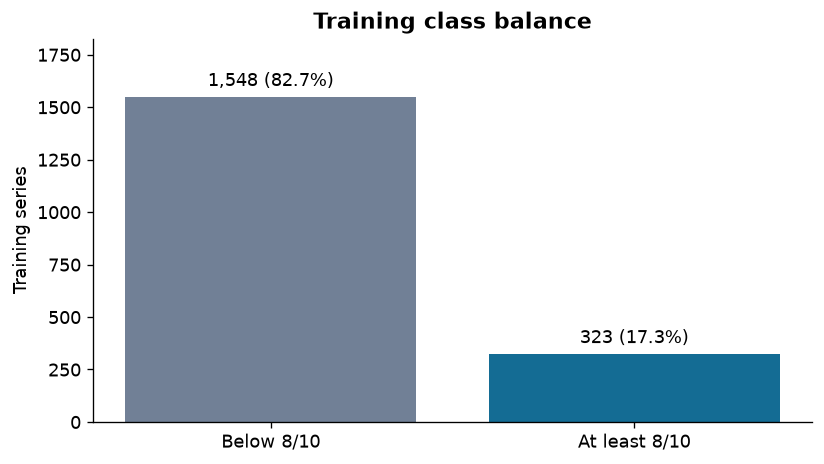

The high-rated class represents **17.3%** of training rows. A majority-only predictor can look good on accuracy while retrieving no high-rated series. We therefore use high-rated-class F1 as the primary metric, preserve class proportions in all splits, and use class weights for Tree and SVM. KNN has no class-weight parameter.

In [6]:
class_counts = train.high_rated.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7,4))
bars = ax.bar(['Below 8/10','At least 8/10'], class_counts.values, color=['#718096','#146C94'])
ax.bar_label(bars, labels=[f'{n:,} ({n/len(train):.1%})' for n in class_counts.values], padding=4)
ax.set_ylabel('Training series')
ax.set_title('Training class balance')
ax.set_ylim(0, class_counts.max()*1.18)
fig.tight_layout(); fig.savefig(FIG/'class_balance.png', bbox_inches='tight'); plt.show()
display(Markdown(f'The high-rated class represents **{y_train.mean():.1%}** of training rows. '
 'A majority-only predictor can look good on accuracy while retrieving no high-rated series. '
 'We therefore use high-rated-class F1 as the primary metric, preserve class proportions in all splits, '
 'and use class weights for Tree and SVM. KNN has no class-weight parameter.'))

,genre,Training series,High-rated share
6,Drama,1150,0.195652
4,Comedy,716,0.129888
5,Crime,435,0.234483
0,Action,320,0.187500
18,Science-Fiction,228,0.223684
2,Adventure,181,0.171271
21,Thriller,164,0.225610
8,Family,160,0.075000
17,Romance,160,0.100000
16,Mystery,157,0.242038


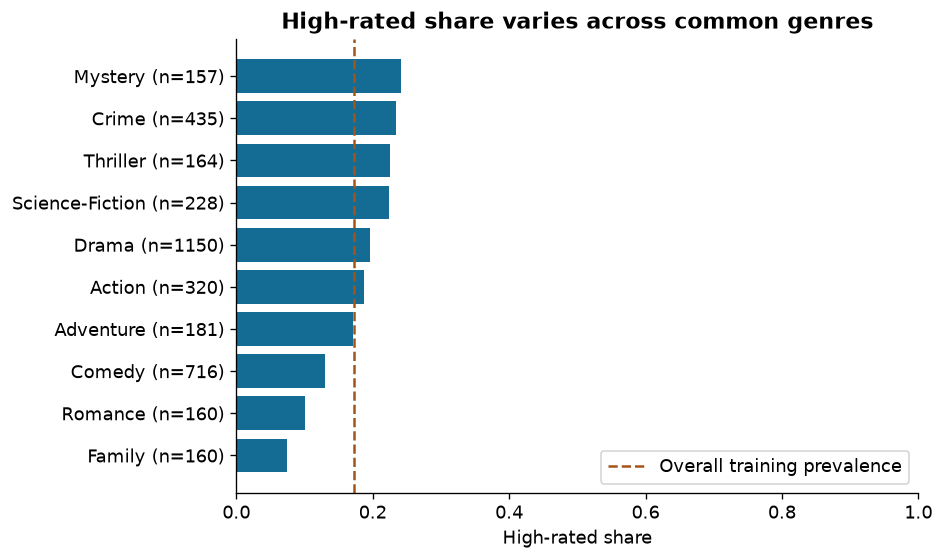

Among these common genres, **Mystery** has a high-rated share of **24.2%**, compared with **7.5%** for **Family**. This supports retaining multi-label genre indicators. A series can occur in several genres, so these groups are not independent. Genre differences do not establish that a genre causes a high score.

In [7]:
genre_rows = []
for _, row in train.iterrows():
    for genre in json.loads(row.genres): genre_rows.append({'genre':genre,'high_rated':row.high_rated})
genre_table = pd.DataFrame(genre_rows).groupby('genre').high_rated.agg(['count','mean']).reset_index()
genre_table = genre_table[genre_table['count']>=30].sort_values('count',ascending=False).head(10)
display(genre_table.rename(columns={'count':'Training series','mean':'High-rated share'}))
fig, ax = plt.subplots(figsize=(8,4.8))
plot_genres = genre_table.sort_values('mean')
ax.barh([f'{g} (n={n})' for g,n in zip(plot_genres.genre,plot_genres['count'])],plot_genres['mean'],color='#146C94')
ax.axvline(y_train.mean(),color='#A45419',linestyle='--',label='Overall training prevalence')
ax.set_xlabel('High-rated share'); ax.set_xlim(0,1)
ax.set_title('High-rated share varies across common genres')
ax.legend(loc='lower right'); fig.tight_layout(); fig.savefig(FIG/'genres.png',bbox_inches='tight'); plt.show()
genre_table.to_csv(OUT/'genre_summary.csv',index=False)
low, high = plot_genres.iloc[0], plot_genres.iloc[-1]
display(Markdown(f'Among these common genres, **{high.genre}** has a high-rated share of **{high["mean"]:.1%}**, '
 f'compared with **{low["mean"]:.1%}** for **{low.genre}**. '
 'This supports retaining multi-label genre indicators. A series can occur in several genres, so these groups are not independent. '
 'Genre differences do not establish that a genre causes a high score.'))

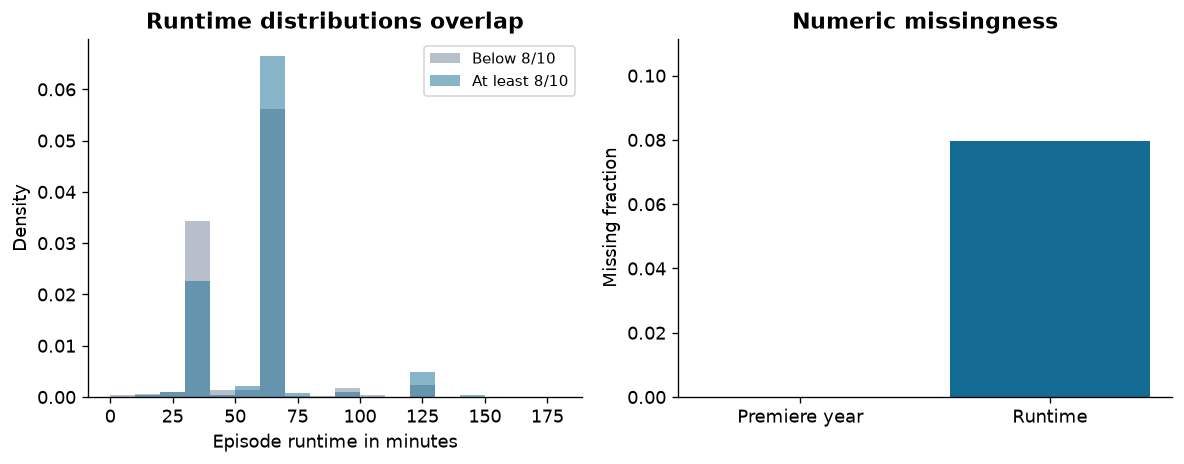

,premiere_year,runtime_minutes
high_rated,,
0,2011.0,60.0
1,2006.0,60.0


Runtime alone does not separate the classes. The plot shows up to 180 minutes for readability; the pipeline retains every positive recorded runtime. Median imputation and missing indicators operate inside each training fold. StandardScaler puts year and runtime on comparable numeric scales for distance-based KNN and SVM.

In [8]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
for label, color, name in [(0,'#718096','Below 8/10'),(1,'#146C94','At least 8/10')]:
    values = train.loc[train.high_rated.eq(label),'runtime_minutes'].dropna()
    axes[0].hist(values, bins=np.arange(0,181,10),density=True,alpha=.5,color=color,label=name)
axes[0].set(xlabel='Episode runtime in minutes',ylabel='Density',title='Runtime distributions overlap')
axes[0].legend(fontsize=9)
missing = train[NUMERIC].isna().mean().rename(index={'premiere_year':'Premiere year','runtime_minutes':'Runtime'})
axes[1].bar(missing.index,missing.values,color='#146C94')
axes[1].set(ylabel='Missing fraction',title='Numeric missingness')
axes[1].set_ylim(0,max(.05,missing.max()*1.4))
fig.tight_layout(); fig.savefig(FIG/'runtime_missingness.png',bbox_inches='tight'); plt.show()
display(train.groupby('high_rated')[NUMERIC].median())
display(Markdown('Runtime alone does not separate the classes. The plot shows up to 180 minutes for readability; '
 'the pipeline retains every positive recorded runtime. Median imputation and missing indicators operate inside each training fold. '
 'StandardScaler puts year and runtime on comparable numeric scales for distance-based KNN and SVM.'))

## 5. Models and cross-validation
Every estimator is a Pipeline. Its ColumnTransformer fits median imputation and missing indicators, numeric scaling where appropriate, one-hot categorical encoding and genre vocabulary on the current training fold only. Rare categorical levels group at **10 training observations**, and unfamiliar levels/genres are handled without exposing validation data.

| Model | Fixed settings and reason |
|---|---|
| Dummy majority | Most frequent class, the accuracy baseline |
| Dummy stratified | Seeded class-frequency sampling, a chance baseline for minority-class F1 |
| Decision Tree | max_depth=6, min_samples_leaf=20, balanced weights, seed 42. Limited depth/leaf size restrain overfitting while allowing interactions |
| KNN | k=15, distance weights, Euclidean distance. A local similarity benchmark with numeric scaling |
| SVM | RBF kernel, C=1, gamma=scale, balanced weights. A regularised nonlinear boundary with numeric scaling |

These parameters are predeclared, not selected on the test set. Larger tuning belongs to Endterm. The primary metric is **F1 for class 1**, balancing missed high-rated series against false shortlist entries. Precision and recall explain that tradeoff. ROC-AUC evaluates ranking, average precision helps under imbalance, and balanced accuracy/accuracy provide context. For SVM, scores are decision margins, not probabilities. Dummy stratified scores are a random baseline, not calibrated probabilities.

In [9]:
models = make_models()
scoring = {'f1':make_scorer(f1_score,zero_division=0),
           'precision':make_scorer(precision_score,zero_division=0),
           'recall':make_scorer(recall_score,zero_division=0),
           'roc_auc':'roc_auc', 'average_precision':'average_precision',
           'balanced_accuracy':'balanced_accuracy', 'accuracy':'accuracy'}
cv_rows, fold_rows = [], []
for name, model in models.items():
    print('Cross-validating',name,flush=True)
    evaluated = cross_validate(model,X_train,y_train,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')
    row = {'model':name}
    for metric in scoring:
        row[f'cv_{metric}_mean'] = float(evaluated[f'test_{metric}'].mean())
        row[f'cv_{metric}_std'] = float(evaluated[f'test_{metric}'].std(ddof=1))
    cv_rows.append(row)
    for fold in range(5):
        fold_rows.append({'model':name,'fold':fold+1,**{metric:float(evaluated[f'test_{metric}'][fold]) for metric in scoring}})
cv_summary = pd.DataFrame(cv_rows)
cv_folds = pd.DataFrame(fold_rows)
display(cv_summary[['model','cv_f1_mean','cv_f1_std','cv_roc_auc_mean','cv_precision_mean','cv_recall_mean']].round(3))
cv_summary.to_csv(OUT/'cv_summary.csv',index=False)
cv_folds.to_csv(OUT/'cv_fold_scores.csv',index=False)

Cross-validating Dummy majority


Cross-validating Dummy stratified


Cross-validating Decision Tree


Cross-validating KNN


Cross-validating SVM


,model,cv_f1_mean,cv_f1_std,cv_roc_auc_mean,cv_precision_mean,cv_recall_mean
0,Dummy majority,0.000,0.000,0.500,0.000,0.000
1,Dummy stratified,0.155,0.034,0.492,0.158,0.152
2,Decision Tree,0.361,0.013,0.663,0.242,0.728
3,KNN,0.157,0.028,0.682,0.450,0.096
4,SVM,0.389,0.017,0.718,0.287,0.610


In [10]:
candidates = cv_summary[~cv_summary.model.str.startswith('Dummy')]
winner = candidates.sort_values(['cv_f1_mean','cv_roc_auc_mean','model'],ascending=[False,False,True]).iloc[0]['model']
decision = {'selected_model':winner,'selection_metric':'Mean training-only 5-fold high-rated-class F1',
            'tie_breaker':'CV ROC-AUC, then model name', 'target_threshold':THRESHOLD, 'random_seed':SEED,
            'features':FEATURES,'decision_threshold':'Estimator default: SVM margin 0; probability models 0.5',
            'parameter_policy':'Predeclared fixed parameters, no test-set tuning',
            'cv_summary_sha256':hashlib.sha256((OUT/'cv_summary.csv').read_bytes()).hexdigest(),
            'split_sha256':hashlib.sha256((ROOT/'data/splits/split_assignments.csv').read_bytes()).hexdigest()}
(OUT/'selection_before_test.json').write_text(json.dumps(decision,indent=2)+'\n')
display(Markdown(f'**Selected before test evaluation: {winner}.** The same frozen cohort, target and split carry forward.'))

**Selected before test evaluation: SVM.** The same frozen cohort, target and split carry forward.

## 6. Held-out results
We now fit each predeclared pipeline on all training rows and evaluate each once on the same untouched test rows. The winner above stays fixed even if another model has a higher test metric. CV spread is the sample standard deviation across five folds, not a confidence interval. The test set supplies one estimate and should not drive further Midterm model changes.

,model,cv_f1_mean,cv_f1_std,test_f1,cv_roc_auc_mean,cv_roc_auc_std,test_roc_auc,test_precision,test_recall,test_accuracy
0,Dummy majority,0.000,0.000,0.000,0.500,0.000,0.500,0.000,0.000,0.827
1,Dummy stratified,0.155,0.034,0.150,0.492,0.020,0.488,0.152,0.148,0.709
2,Decision Tree,0.361,0.013,0.300,0.663,0.017,0.563,0.199,0.605,0.511
3,KNN,0.157,0.028,0.231,0.682,0.047,0.644,0.522,0.148,0.829
4,SVM,0.389,0.017,0.340,0.718,0.011,0.643,0.256,0.506,0.660


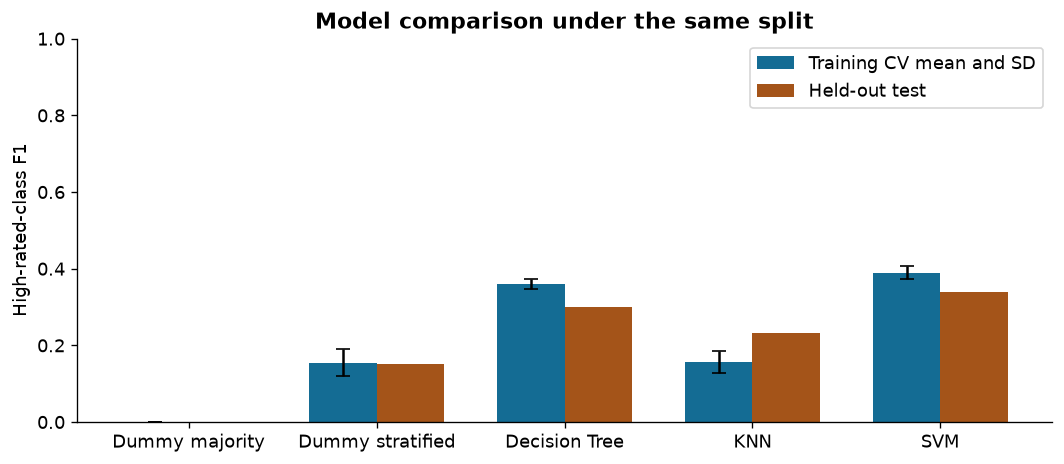

In [11]:
test_rows, fitted, predictions = [], {}, {}
for name, model in models.items():
    model.fit(X_train,y_train)
    predicted = model.predict(X_test)
    scores = positive_scores(model,X_test)
    fitted[name] = model
    predictions[name] = (predicted,scores)
    test_rows.append({'model':name,'test_f1':f1_score(y_test,predicted,zero_division=0),
       'test_precision':precision_score(y_test,predicted,zero_division=0),
       'test_recall':recall_score(y_test,predicted,zero_division=0),
       'test_roc_auc':roc_auc_score(y_test,scores), 'test_average_precision':average_precision_score(y_test,scores),
       'test_balanced_accuracy':balanced_accuracy_score(y_test,predicted),'test_accuracy':accuracy_score(y_test,predicted)})
results = cv_summary.merge(pd.DataFrame(test_rows),on='model',validate='one_to_one')
display(results[['model','cv_f1_mean','cv_f1_std','test_f1','cv_roc_auc_mean','cv_roc_auc_std',
                 'test_roc_auc','test_precision','test_recall','test_accuracy']].round(3))
results.to_csv(OUT/'model_comparison.csv',index=False)
joblib.dump(fitted[winner], ROOT/'models/midterm_model.joblib')
fig, ax = plt.subplots(figsize=(9,4))
order = results.model.tolist(); x = np.arange(len(order))
ax.bar(x-.18,results.cv_f1_mean,.36,yerr=results.cv_f1_std,capsize=4,label='Training CV mean and SD',color='#146C94')
ax.bar(x+.18,results.test_f1,.36,label='Held-out test',color='#A45419')
ax.set(xticks=x,xticklabels=order,ylabel='High-rated-class F1',ylim=(0,1),title='Model comparison under the same split')
ax.legend(); fig.tight_layout(); fig.savefig(FIG/'model_comparison.png',bbox_inches='tight'); plt.show()

## 7. Error analysis and real examples
We analyse the CV-selected model's confusion matrix and concrete false positives/negatives. Score values indicate ordering and confidence relative to a decision boundary. They do not measure the true probability that a show will receive a future rating. Example selection is deterministic: two highest-scoring false positives and two lowest-scoring false negatives, followed by one correct example from each class.

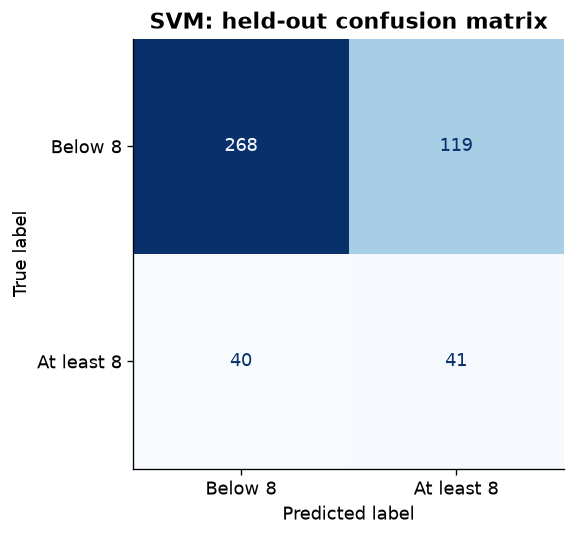

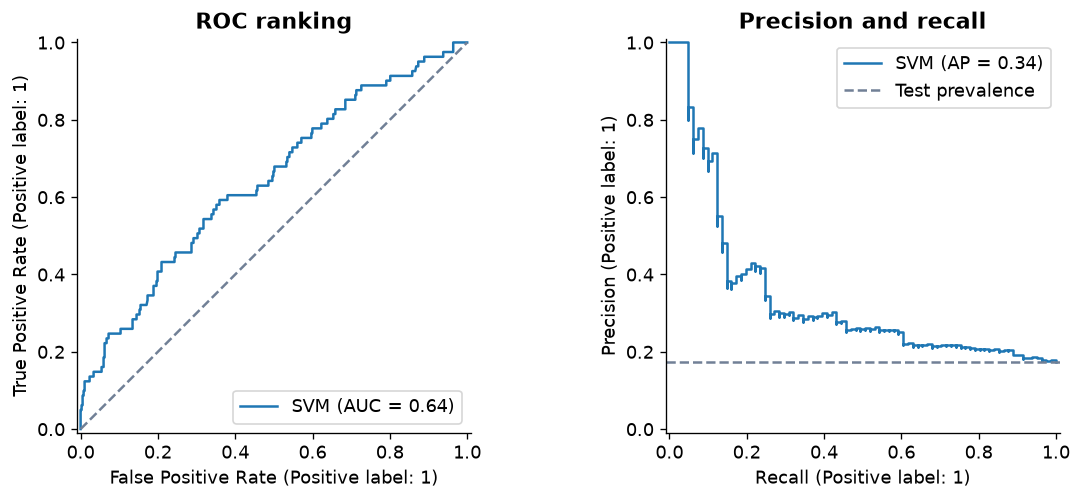

,name,rating,predicted_high_rated,score,outcome,genres,network
217,Touching Evil,7.1,1,1.312,False positive,"[""Crime"", ""Drama"", ""Thriller""]",USA Network
70,The Prisoner,6.9,1,1.228,False positive,"[""Drama"", ""Mystery"", ""Science-Fiction""]",AMC
43,Community,8.3,0,-1.627,False negative,"[""Comedy""]",Unknown
96,Rules of Engagement,8.0,0,-1.616,False negative,"[""Comedy"", ""Romance""]",CBS
0,Person of Interest,8.8,1,0.015,True positive,"[""Action"", ""Crime"", ""Science-Fiction""]",CBS
1,Bitten,7.4,0,-1.033,True negative,"[""Drama"", ""Horror"", ""Romance""]",CTV Sci-Fi Channel


The selected model finds **41 of 81** high-rated test series and misses **40**. It incorrectly shortlists **119** below-threshold series. Similar genres, runtime and channels do not reveal acting, writing quality or individual audience taste. This is a plausible explanation for the displayed failures, not a causal diagnosis of each show. TVmaze does not supply vote counts in this endpoint, so we cannot assess rating reliability or exclude low-vote labels.

In [12]:
predicted, scores = predictions[winner]
cm = confusion_matrix(y_test,predicted,labels=[0,1])
fig, ax = plt.subplots(figsize=(6,4.6))
ConfusionMatrixDisplay(cm,display_labels=['Below 8','At least 8']).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title(f'{winner}: held-out confusion matrix')
fig.tight_layout(); fig.savefig(FIG/'confusion_matrix.png',bbox_inches='tight'); plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,4.3))
RocCurveDisplay.from_predictions(y_test,scores,ax=axes[0],name=winner)
axes[0].plot([0,1],[0,1],'--',color='#718096'); axes[0].set_title('ROC ranking')
PrecisionRecallDisplay.from_predictions(y_test,scores,ax=axes[1],name=winner)
axes[1].axhline(y_test.mean(),linestyle='--',color='#718096',label='Test prevalence')
axes[1].set_title('Precision and recall'); axes[1].legend()
fig.tight_layout(); fig.savefig(FIG/'ranking_curves.png',bbox_inches='tight'); plt.show()
audit = test[['show_id','name','rating','high_rated','genres','runtime_minutes','premiere_year','network','source_url']].copy()
audit['predicted_high_rated'] = predicted
audit['score'] = scores
audit['outcome'] = np.select([(audit.high_rated==0)&(predicted==1),(audit.high_rated==1)&(predicted==0),
                              (audit.high_rated==1)&(predicted==1)],['False positive','False negative','True positive'],default='True negative')
examples = pd.concat([audit[audit.outcome.eq('False positive')].sort_values('score',ascending=False).head(2),
                      audit[audit.outcome.eq('False negative')].sort_values('score').head(2),
                      audit[audit.outcome.eq('True positive')].sort_values('show_id').head(1),
                      audit[audit.outcome.eq('True negative')].sort_values('show_id').head(1)])
display(examples[['name','rating','predicted_high_rated','score','outcome','genres','network']].round({'score':3}))
audit.to_csv(OUT/'test_predictions.csv',index=False)
examples.to_csv(OUT/'error_examples.csv',index=False)
tn,fp,fn,tp = cm.ravel()
display(Markdown(f'The selected model finds **{tp} of {tp+fn}** high-rated test series and misses **{fn}**. '
 f'It incorrectly shortlists **{fp}** below-threshold series. '
 'Similar genres, runtime and channels do not reveal acting, writing quality or individual audience taste. '
 'This is a plausible explanation for the displayed failures, not a causal diagnosis of each show. '
 'TVmaze does not supply vote counts in this endpoint, so we cannot assess rating reliability or exclude low-vote labels.'))

In [13]:
subgroups = []
for column in ['broadcast_country','distribution']:
    for group, values in test.assign(predicted=predicted).groupby(column):
        if len(values) >= 30:
            subgroups.append({'field':column,'group':group,'rows':len(values),
                'high_rated_share':values.high_rated.mean(),
                'f1':f1_score(values.high_rated,values.predicted,zero_division=0),
                'recall':recall_score(values.high_rated,values.predicted,zero_division=0)})
subgroup_table = pd.DataFrame(subgroups)
display(subgroup_table.round(3))
subgroup_table.to_csv(OUT/'subgroup_results.csv',index=False)
display(Markdown('Subgroup scores are descriptive diagnostics for groups with at least 30 test observations. '
 'Small groups and minority-positive counts make comparisons uncertain. We do not use these test diagnostics to retune this Midterm model.'))

,field,group,rows,high_rated_share,f1,recall
0,broadcast_country,GB,114,0.193,0.447,0.773
1,broadcast_country,US,291,0.165,0.273,0.375
2,distribution,Broadcast,424,0.170,0.335,0.514
3,distribution,Streaming,41,0.220,0.400,0.444


Subgroup scores are descriptive diagnostics for groups with at least 30 test observations. Small groups and minority-positive counts make comparisons uncertain. We do not use these test diagnostics to retune this Midterm model.

## 8. Conclusions, limitations and continuation
The output below answers the registered question with the measured results. Useful metadata association can support a shortlist, but it cannot replace viewer judgement. This is an observational catalogue experiment, not a causal explanation or a validated prediction of future popularity.

Concrete limitations: rated English scripted shows only; sequential early index pages rather than a representative population sample; current channel metadata may differ from original release metadata; subjective labels with unknown vote counts; a hard boundary makes 7.9 and 8.0 opposite classes; a fixed random split cannot establish performance on genuinely new releases or unrated shows. Related franchises may remain across partitions despite unique IDs. The limited minority class can produce unstable subgroup results.

In [14]:
selected = results[results.model.eq(winner)].iloc[0]
chance = results[results.model.eq('Dummy stratified')].iloc[0]
delta = selected.test_f1-chance.test_f1
direction = 'above' if delta>=0 else 'below'
conclusion = (f'{winner} was selected using training CV F1. Its CV F1 is {selected.cv_f1_mean:.3f} '
 f'(SD {selected.cv_f1_std:.3f}); test F1 is {selected.test_f1:.3f}, '
 f'{abs(delta):.3f} {direction} the stratified chance baseline. '
 f'Test ROC-AUC is {selected.test_roc_auc:.3f}, precision is {selected.test_precision:.3f} '
 f'and recall is {selected.test_recall:.3f}. '
 'The structured metadata carry some ranking information if ROC-AUC exceeds 0.5, while the confusion matrix quantifies practical mistakes. '
 'The proposed use for unrated series requires a separate validation study.')
display(Markdown(conclusion))
plan = pd.DataFrame([
 {'Stage':'Endterm, ensembles and tuning','Observed weakness':f'{fp} false positives and {fn} false negatives with simple fixed models',
  'Action':'Compare Random Forest and Gradient Boosting with training-only GridSearchCV on frozen folds; tune the precision/recall tradeoff using training predictions only.'},
 {'Stage':'Endterm, clustering and PCA','Observed weakness':'Metadata overlap and small/uneven subgroups',
  'Action':'Fit PCA and K-Means on training features to inspect metadata segments, then describe held-out errors by segment without using labels to form clusters.'},
 {'Stage':'Endterm, neural network','Observed weakness':'Simple models may miss feature interactions; minority labels are limited',
  'Action':'Compare a small regularised MLP with early stopping inside training. Use learning curves to check overfitting.'},
 {'Stage':'Final, text and local app','Observed weakness':'Metadata omit plot themes and story information',
  'Action':'Add train-fitted TF-IDF or text embeddings from the retained summaries and compare with metadata-only on identical frozen IDs. Package a local app, report and defense.'}])
display(plan)
plan.to_csv(OUT/'continuation_plan.csv',index=False)
summary = {'source':'TVmaze, https://www.tvmaze.com','license':'CC BY-SA 4.0',
 'collection_date':manifest['collection_date_almaty'],'raw_rows':len(raw),'clean_rows':len(clean),
 'positive_rows':int(clean.high_rated.sum()),'positive_share':float(clean.high_rated.mean()),
 'train_rows':len(train),'test_rows':len(test),'train_positive_rows':int(y_train.sum()),
 'test_positive_rows':int(y_test.sum()),'winner':winner,'confusion_matrix':cm.tolist(),
 'features':FEATURES,'models':results.to_dict('records'),'genre_summary':genre_table.to_dict('records'),
 'examples':examples.fillna('').to_dict('records'),'conclusion':conclusion,
 'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit-learn':sklearn.__version__},
 'clean_csv_sha256':hashlib.sha256(clean_path.read_bytes()).hexdigest(),
 'split_sha256':hashlib.sha256((ROOT/'data/splits/split_assignments.csv').read_bytes()).hexdigest()}
(OUT/'experiment_summary.json').write_text(json.dumps(summary,indent=2)+'\n')
print('Saved results, model, real examples and continuation plan. The test split remains frozen.')

SVM was selected using training CV F1. Its CV F1 is 0.389 (SD 0.017); test F1 is 0.340, 0.190 above the stratified chance baseline. Test ROC-AUC is 0.643, precision is 0.256 and recall is 0.506. The structured metadata carry some ranking information if ROC-AUC exceeds 0.5, while the confusion matrix quantifies practical mistakes. The proposed use for unrated series requires a separate validation study.

,Stage,Observed weakness,Action
0,"Endterm, ensembles and tuning",119 false positives and 40 false negatives wit...,Compare Random Forest and Gradient Boosting wi...
1,"Endterm, clustering and PCA",Metadata overlap and small/uneven subgroups,Fit PCA and K-Means on training features to in...
2,"Endterm, neural network",Simple models may miss feature interactions; m...,Compare a small regularised MLP with early sto...
3,"Final, text and local app",Metadata omit plot themes and story information,Add train-fitted TF-IDF or text embeddings fro...


Saved results, model, real examples and continuation plan. The test split remains frozen.


## 9. Contributions and AI assistance
Team responsibilities confirmed by Bekzat on 6 October 2026:

- **Bekzat Rashiduly:** data collection and source checks, model workflow, results and error analysis.
- **Gapar Galym:** data preparation and exploration, presentation preparation and delivery.
- **Both members:** review the full notebook, validate the conclusions and prepare to answer questions about every part, including the partner's area.

**AI disclosure:** OpenAI Codex assisted with source research, collector and preprocessing code, notebook authoring, model execution, calculations, slide drafting, quality checks and defense-study materials. These materials and experiments were prepared with AI assistance under Bekzat's direction. The allocation above records responsibility for reviewing and defending the work. Both members remain responsible for the submitted content and their own understanding.

References: TVmaze public API, https://www.tvmaze.com/api; CC BY-SA 4.0, https://creativecommons.org/licenses/by-sa/4.0/; AITU Course Project Guide and Midterm Rubric supplied in Moodle; scikit-learn documentation, https://scikit-learn.org/stable/.